In [68]:
import os
import os.path as op

import matplotlib.pyplot as plt

import hnn_core
from hnn_core.params import _short_name

from hnn_core import new_calcium_model, simulate_dipole, read_dipole, MPIBackend, jones_2009_model

from hnn_core.optimization import Optimizer
import numpy as np
hnn_core_root = op.join(op.dirname(hnn_core.__file__))
pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_model_HNN/figures/'

# The number of cores may need modifying depending on your current machine.
n_procs = 6

In [69]:
exp_dpl = read_dipole('/Users/katharinaduecker/Documents/projects_brown/hnn-data/MEG_detection_data/S1_SupraT.txt')

## Handtune

In [70]:

prox1_weights_ampa = {'L2_basket': 0.009355766425012867*0.5,
                        'L2_pyramidal': 0.017821964058181386*0.4,
                        'L5_basket': 0.06360458875185422*2,
                        'L5_pyramidal': 0.19529920430756656}
prox1_weights_nmda = {'L2_basket': 0.0019710468589739668*0.1,
                        'L2_pyramidal': 0.005363307709092387*0.2,
                        'L5_basket': 0.004440122026440295,
                        'L5_pyramidal': 0.11613875475625732*0.02}

dist_weights_ampa = {'L2_basket': 0.0034061998909488485,
                    'L2_pyramidal': 0.04571263358904524*14,
                    'L5_pyramidal': 0.03070737911180561*14}
dist_weights_nmda = {'L2_basket': 0.0032451182438157145,
                    'L2_pyramidal': 0.023128505130650276*4,
                    'L5_pyramidal': 0.23013679176569424*4}

prox2_weights_ampa = {'L2_basket': 0.0068621596378251855,
                        'L2_pyramidal': 0.03098179455638236,
                        'L5_basket': 0.0028128946269181136,
                        'L5_pyramidal': 0.6487065801685004}
prox2_weights_nmda = {'L2_basket': 0.009409301539150934,
                    'L2_pyramidal': 0.12711473194831402,
                    'L5_basket': 0.00028935388454280175,
                    'L5_pyramidal': 0.3419028116089666}



In [71]:
tstop = exp_dpl.times[-1]
scale_factor = 1000
smooth_window_len = 10

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...
Trial 1: 100.0 ms...
Trial 1: 110.0 ms...
Trial 1: 120.0 ms...
Trial 1: 130.0 ms...
Trial 1: 140.0 ms...
Trial 1: 150.0 ms...
Trial 1: 160.0 ms...
Trial 1: 170.0 ms...


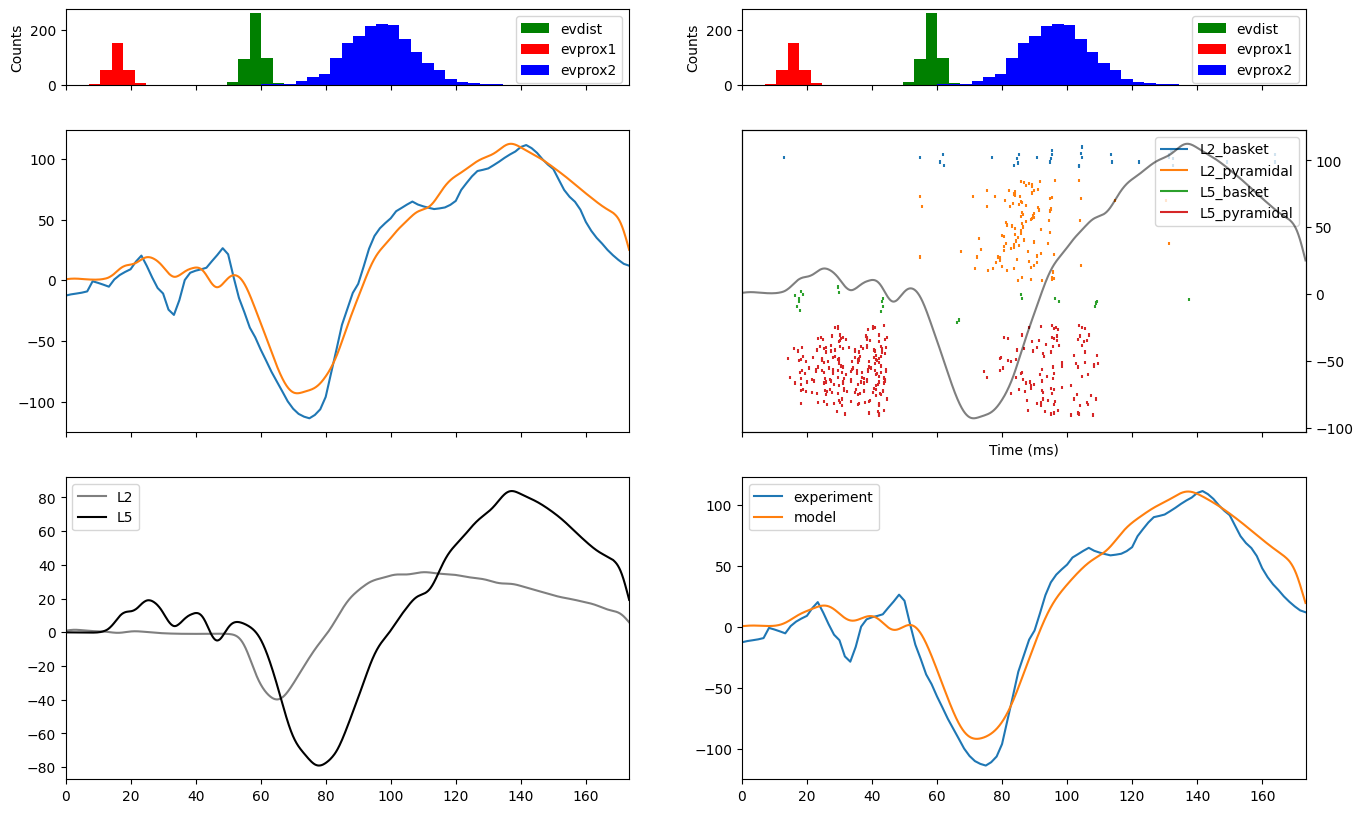

In [72]:


net_init = new_calcium_model()
# net_init.set_cell_positions(inplane_distance=30.)

# depths = list(list(range(-100,2400,200)))
# electrode_pos = [(135, 135, dep) for dep in depths]

# net_init.add_electrode_array('probe1', electrode_pos)

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
net_init.add_evoked_drive('evprox1',
                        mu=16.,
                        sigma=2.3,
                        numspikes=1,
                        location='proximal',
                        weights_ampa=prox1_weights_ampa,
                        weights_nmda=prox1_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)

# Distal
synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

net_init.add_evoked_drive('evdist',
                        mu=58.5,
                        sigma=2.5,
                        numspikes=2,
                        location='distal',
                        weights_ampa=dist_weights_ampa,
                        weights_nmda=dist_weights_nmda,
                        synaptic_delays=synaptic_delays_d, event_seed=544)

net_init.add_evoked_drive('evprox2',
                    mu=97,
                    sigma=10,
                    numspikes=6,
                    location='proximal',
                    weights_ampa=prox2_weights_ampa,
                    weights_nmda=prox2_weights_nmda,
                    synaptic_delays=synaptic_delays_p, event_seed=544)
init_dpl = simulate_dipole(net_init, tstop=tstop, n_trials=1,bsl_cor='calcium', record_vsec='all', record_isec='all')[0]

init_dpl.scale(scale_factor).smooth(smooth_window_len)


fig, ax = plt.subplots(3,2,figsize=(16,10), height_ratios=[0.25,1,1], sharex=True)

net_init.cell_response.plot_spikes_hist(ax=ax[0,0], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)
net_init.cell_response.plot_spikes_hist(ax=ax[0,1], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)


ax[1,0].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

ax[1,0].plot(init_dpl.times,init_dpl.data['agg'], label='model')

net_init.cell_response.plot_spikes_raster(ax=ax[1,1], show=False)
ax2 = ax[1,1].twinx()
ax2.plot(init_dpl.times,init_dpl.data['agg'],color='k', alpha=0.5)

ax[2,0].plot(init_dpl.times,init_dpl.data['L2'], label='L2', color='k', alpha=0.5)
ax[2,0].plot(init_dpl.times,init_dpl.data['L5'], label='L5', color='k')
ax[2,0].legend()

ax[2,1].plot(exp_dpl.times,exp_dpl.data['agg'], label='experiment')

smooth_dpl = init_dpl.smooth(smooth_window_len)
ax[2,1].plot(smooth_dpl.times,smooth_dpl.data['agg'], label='model')
ax[2,1].legend()


fig.savefig(os.path.join(pathfig,'initial_dpl.png'))

In [73]:
from hnn_core.dipole import _rmse

init_rmse = _rmse(init_dpl, exp_dpl,tstart=0,tstop=1000)

init_rmse

np.float64(16.192066361141727)

## Optimize

### Strength of drives

In [74]:
def set_params(net, params):

    # Proximal 1
    synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}
    
    weights_ampa_p1 = {'L2_basket':
                       params['evprox1_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_ampa_L5_pyramidal']}
    weights_nmda_p1 = {'L2_basket':
                       params['evprox1_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox1_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox1_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox1_nmda_L5_pyramidal']}

    
    net.add_evoked_drive('evprox1',
                         mu=16,
                         sigma=2.3,
                         numspikes=1,
                         location='proximal',
                         weights_ampa=weights_ampa_p1,
                         weights_nmda=weights_nmda_p1,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}
    
    weights_ampa_d = {'L2_basket':
                       params['evdist_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_ampa_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_ampa_L5_pyramidal']}
    weights_nmda_d = {'L2_basket':
                       params['evdist_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evdist_nmda_L2_pyramidal'],
                       'L5_pyramidal':
                       params['evdist_nmda_L5_pyramidal']}
    

    net.add_evoked_drive('evdist',
                         mu=58.5,
                        sigma=2.5,
                        numspikes=1,
                         location='distal',
                         weights_ampa=weights_ampa_d,
                         weights_nmda=weights_nmda_d,
                         synaptic_delays=synaptic_delays_d, event_seed=544)


    weights_ampa_p2 = {'L2_basket':
                       params['evprox2_ampa_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_ampa_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_ampa_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_ampa_L5_pyramidal']}
    weights_nmda_p2 = {'L2_basket':
                       params['evprox2_nmda_L2_basket'],
                       'L2_pyramidal':
                       params['evprox2_nmda_L2_pyramidal'],
                       'L5_basket':
                       params['evprox2_nmda_L5_basket'],
                       'L5_pyramidal':
                       params['evprox2_nmda_L5_pyramidal']}
    
    net.add_evoked_drive('evprox2',
                        mu=97,
                        sigma=10,
                        numspikes=6,
                        location='proximal',
                        weights_ampa=weights_ampa_p2,
                        weights_nmda=weights_nmda_p2,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay



# constrain such that L5 is driven more than L2
constraints = dict({'evprox1_ampa_L2_basket': (0.0001, 0.01),
                'evprox1_ampa_L2_pyramidal': (0.0005, 0.02),
                'evprox1_ampa_L5_basket': (0.05, 0.3),
                'evprox1_ampa_L5_pyramidal': (0.01, .4),

                'evprox1_nmda_L2_basket': (0.00005, 0.01),
                'evprox1_nmda_L2_pyramidal': (0.00005, 0.001),
                'evprox1_nmda_L5_basket': (0.0001, 0.05),
                'evprox1_nmda_L5_pyramidal': (0.0005, 0.1),


                'evdist_ampa_L2_basket': (0.0003, 0.01),
                'evdist_ampa_L2_pyramidal': (0.03, 1.),
                'evdist_ampa_L5_pyramidal': (0.03, 1.),
                'evdist_nmda_L2_basket': (9e-5, 1e-2),
                'evdist_nmda_L2_pyramidal': (0.4, 1.),
                'evdist_nmda_L5_pyramidal': (0.1, 1.),

                'evprox2_nmda_L2_basket': (9e-3, 1e-2),
                'evprox2_nmda_L2_pyramidal': (0.03, .05),
                'evprox2_nmda_L5_basket': (2e-4, 4e-4),
                'evprox2_nmda_L5_pyramidal': (0.1, 0.3),
                'evprox2_ampa_L2_basket': (5e-3, 1e-2),
                'evprox2_ampa_L2_pyramidal': (0.1, .2),
                'evprox2_ampa_L5_basket': (2e-3, 1e-2),
                'evprox2_ampa_L5_pyramidal': (0.5, .8)})
    


MPI will run 1 trial(s) sequentially by distributing network neurons over 6 processes.
numprocs=6
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/kat

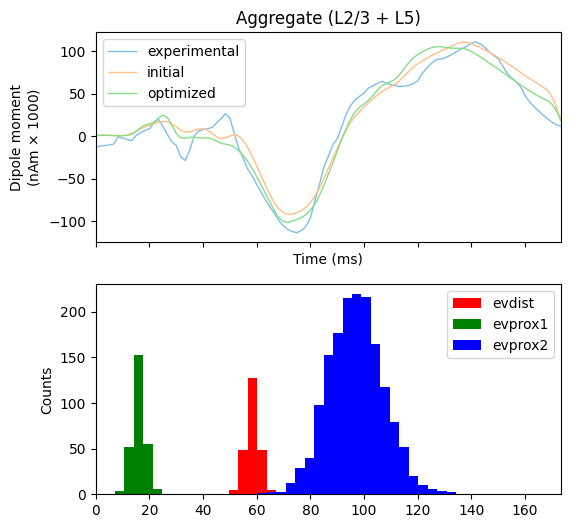

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/optimization/general_optimization.py:182: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show(show)


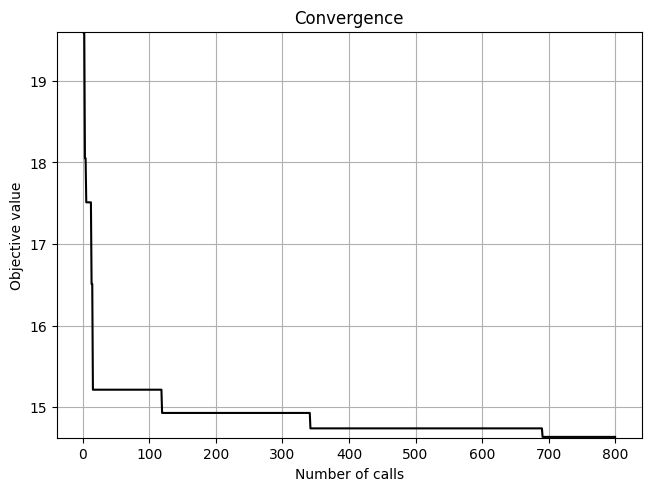

In [75]:
net = new_calcium_model()
optim = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params, solver='bayesian', obj_fun='dipole_rmse', max_iter=800)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim.plot_convergence()

In [76]:
init_rmse = _rmse(init_dpl, exp_dpl, tstart=0, tstop=1000)
opt_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)


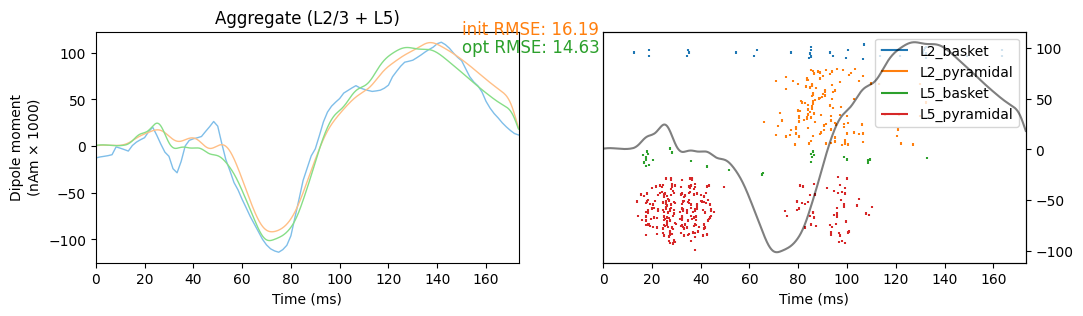

In [77]:
fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
axes[0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].text(150,100, f'opt RMSE: {opt_rmse:.2f}', fontsize=12, color='tab:green')

optim.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
ax2 = axes[1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

In [78]:
prox2_ampa = optim.net_.external_drives['evprox2']['weights_ampa']
prox2_nmda = optim.net_.external_drives['evprox2']['weights_nmda']

dist_ampa = optim.net_.external_drives['evdist']['weights_ampa']
dist_nmda = optim.net_.external_drives['evdist']['weights_nmda']

prox1_ampa = optim.net_.external_drives['evprox1']['weights_ampa']
prox1_nmda = optim.net_.external_drives['evprox1']['weights_nmda']

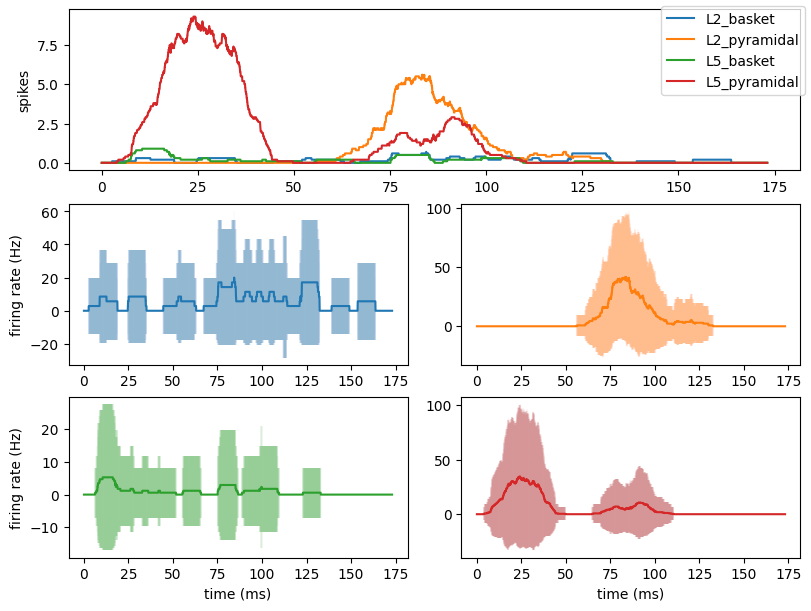

In [79]:
fig = plt.figure(figsize=(8, 6), layout="constrained")
spec = fig.add_gridspec(3, 2)

ax0 = fig.add_subplot(spec[0, :])

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[1, 0])

ax1[1] = fig.add_subplot(spec[1, 1])

ax1[2] = fig.add_subplot(spec[2, 0])

ax1[3] = fig.add_subplot(spec[2, 1])


frates_all = np.zeros((4, len(optim.net_.cell_response.times)-smooth_window_len))

cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
for i, cell_type in enumerate(cell_types):

    frates_cell = np.zeros((max(optim.net_.gid_ranges[cell_type])+1, len(optim.net_.cell_response.times)-smooth_window_len))
    # Get the spike times for the current cell type
    spike_times_type = np.array(optim.net_.cell_response.spike_times_by_type[cell_type][0])
    spike_times = np.array(optim.net_.cell_response.spike_times[0])
    spike_gids = np.array(optim.net_.cell_response.spike_gids[0])
    for ti, t in enumerate(optim.net_.cell_response.times[:-smooth_window_len]):
        frates_all[i, ti] = np.sum((spike_times_type > t) & (spike_times_type < t + smooth_window_len))/smooth_window_len
        spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)
        if (spike_bool).any():
            for g, gid in enumerate(optim.net_.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])/smooth_window_len*1000
    ax0.plot(optim.net_.cell_response.times[:-smooth_window_len], frates_all[i, :])
    ax1[i].errorbar(optim.net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), np.std(frates_cell, axis=0), alpha=0.01, color=cols[i])
    ax1[i].plot(optim.net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), color=cols[i],label=cell_type)
    
ax0.set_ylabel('spikes')
ax1[0].set_ylabel('firing rate (Hz)')
ax1[2].set_ylabel('firing rate (Hz)')
ax1[2].set_xlabel('time (ms)')
ax1[3].set_xlabel('time (ms)')
fig.legend()


### Timing of drives

In [80]:
prox1_weights_ampa = optim.net_.external_drives['evprox1']['weights_ampa']
prox1_weights_nmda = optim.net_.external_drives['evprox1']['weights_nmda']

dist_weights_ampa = optim.net_.external_drives['evdist']['weights_ampa']
dist_weights_nmda = optim.net_.external_drives['evdist']['weights_nmda']

prox2_weights_ampa = optim.net_.external_drives['evprox2']['weights_ampa']
prox2_weights_nmda = optim.net_.external_drives['evprox2']['weights_nmda']

synaptic_delays_p = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                     'L5_basket': 1., 'L5_pyramidal': 1.}

synaptic_delays_d = {'L2_basket': 0.1, 'L2_pyramidal': 0.1, 'L5_pyramidal': 1.}

def set_params_time(net, params):

    # Proximal 1
    
    net.add_evoked_drive('evprox1',
                         mu=params['evprox1_mu'],
                         sigma=params['evprox1_sigma'],
                         numspikes=1,
                         location='proximal',
                         weights_ampa=prox1_weights_ampa,
                         weights_nmda=prox1_weights_nmda,
                         synaptic_delays=synaptic_delays_p, event_seed=544)

    # Distal
    
    net.add_evoked_drive('evdist',
                         mu=params['evdist_mu'],
                         sigma=params['evdist_sigma'],
                         numspikes=int(np.round(params['evdist_num_spikes'])),
                         location='distal',
                         weights_ampa=dist_weights_ampa,
                         weights_nmda=dist_weights_nmda,
                         synaptic_delays=synaptic_delays_d, event_seed=544)
    
    net.add_evoked_drive('evprox2',
                        mu=params['evprox2_mu'],
                        sigma=params['evprox2_sigma'],
                        numspikes=int(np.round(params['evprox2_num_spikes'])),
                        location='proximal',
                        weights_ampa=prox2_weights_ampa,
                        weights_nmda=prox2_weights_nmda,
                        synaptic_delays=synaptic_delays_p, event_seed=544)
    
    delay = net.delay


constraints = dict({'evprox1_mu': (15, 21),
                'evprox1_sigma': (2., 4),

                'evdist_mu': (57, 62),
                'evdist_sigma': (2, 3),
                'evdist_num_spikes': (1, 2),

                'evprox2_mu': (94, 105),
                'evprox2_sigma': (8, 12),
                'evprox2_num_spikes': (1, 8)})

In [81]:
net = new_calcium_model()
optim_time = Optimizer(net, tstop=tstop, constraints=constraints,
                  set_params=set_params_time, solver='bayesian', obj_fun='dipole_rmse', max_iter=500)

with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    optim_time.fit(target=exp_dpl, scale_factor=scale_factor,
              smooth_window_len=smooth_window_len,bsl_cor='calcium')
    
with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
    opt_dpl = simulate_dipole(optim_time.net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
opt_dpl.scale(scale_factor)
opt_dpl.smooth(smooth_window_len)

fig, axes = plt.subplots(2, 1, sharex=True, figsize=(6, 6))

# plot original
exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')
axes[0].legend(['experimental', 'initial', 'optimized'])
optim_time.net_.cell_response.plot_spikes_hist(ax=axes[1])

fig1 = optim_time.plot_convergence()

MPI will run 1 trial(s) sequentially by distributing network neurons over 6 processes.
numprocs=6
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/katharinaduecker/miniconda3/envs/local_hnn/bin/nrniv:10: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import working_set
/Users/kat

/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/parallel_backends.py:209: UserWarning: Received KeyboardInterrupt. Stopping simulation process...
  warn("Received KeyboardInterrupt. Stopping simulation process...")


RuntimeError: MPI simulation failed. Return code: 1

In [ ]:
# import pickle
# with open('optim_time.pkl', 'rb') as file:
#         net_ = pickle.load(file)

In [ ]:
# with MPIBackend(n_procs=n_procs, mpi_cmd='mpiexec'):
#     opt_dpl = simulate_dipole(net_, tstop=tstop, n_trials=1,bsl_cor='calcium')[0]
# opt_dpl.scale(scale_factor)
# opt_dpl.smooth(smooth_window_len)

In [ ]:
# opt_time_rmse = _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)


In [ ]:
fig, axes = plt.subplots(2,2,figsize=(14, 5), sharex=True, height_ratios=[0.25,1])

optim.net_.cell_response.plot_spikes_hist(ax=axes[0,0], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)
optim.net_.cell_response.plot_spikes_hist(ax=axes[0,1], spike_types=['evprox1', 'evdist', 'evprox2'], show=False)


exp_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:blue')
init_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:orange')
axes[1,0].text(150,120, f'init RMSE: {init_rmse:.2f}', fontsize=12, color='tab:orange')
opt_dpl.plot(ax=axes[1,0], layer='agg', show=False, color='tab:green')
axes[1,0].text(150,100, f'opt RMSE: {opt_time_rmse:.2f}', fontsize=12, color='tab:green')

optim.net_.cell_response.plot_spikes_raster(ax=axes[1,1], show=False)
ax2 = axes[1,1].twinx()
ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)

fig.savefig(os.path.join(pathfig,'optimized_dpl_round2.png'))
fig.savefig(os.path.join(pathfig,'optimized_dpl_round2.svg'))

In [ ]:
smooth_window_len = 10


In [ ]:
fig = plt.figure(figsize=(8, 6), layout="constrained")
spec = fig.add_gridspec(4, 2)

ax0 = fig.add_subplot(spec[0, :])

ax1 = [None] * 4
ax1[0] = fig.add_subplot(spec[1, 0])

ax1[1] = fig.add_subplot(spec[1, 1])

ax1[2] = fig.add_subplot(spec[2, 0])

ax1[3] = fig.add_subplot(spec[2, 1])

ax2 = fig.add_subplot(spec[3, :])


frates_type = np.zeros((4, len(net_.cell_response.times)-smooth_window_len))
frates_all = np.zeros((len(net_.cell_response.times)-smooth_window_len,))
cols = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']
cell_types = ['L2_basket', 'L2_pyramidal', 'L5_basket', 'L5_pyramidal']
spike_times = np.array(net_.cell_response.spike_times[0])
spike_gids = np.array(net_.cell_response.spike_gids[0])


for i, cell_type in enumerate(cell_types):
    frates_cell = np.zeros((max(net_.gid_ranges[cell_type])+1, len(net_.cell_response.times)-smooth_window_len))
    for ti, t in enumerate(net_.cell_response.times[:-smooth_window_len]):
        spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)

        
        # Get the spike times for the current cell type
        spike_times_type = np.array(net_.cell_response.spike_times_by_type[cell_type][0])

        frates_type[i, ti] = np.sum((spike_times_type > t) & (spike_times_type < t + smooth_window_len))/smooth_window_len
        
        if (spike_bool).any():
            for g, gid in enumerate(net_.gid_ranges[cell_type]):
                frates_cell[g, ti] = np.sum(gid == spike_gids[spike_bool])/smooth_window_len*1000
    ax0.plot(net_.cell_response.times[:-smooth_window_len], frates_type[i, :])
    ax1[i].errorbar(net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), np.std(frates_cell, axis=0), alpha=0.01, color=cols[i])
    ax1[i].plot(net_.cell_response.times[:-smooth_window_len], np.mean(frates_cell, axis=0), color=cols[i],label=cell_type)

for ti, t in enumerate(net_.cell_response.times[:-smooth_window_len]):
    spike_bool = (spike_times > t) & (spike_times < t + smooth_window_len)
    frates_all[ti] = np.sum((spike_times > t) & (spike_times < t + smooth_window_len))/smooth_window_len
ax0.set_ylabel('spikes')
ax1[0].set_ylabel('firing rate (Hz)')
ax1[2].set_ylabel('firing rate (Hz)')
ax1[2].set_xlabel('time (ms)')
ax1[3].set_xlabel('time (ms)')
ax2.plot(net_.cell_response.times[:-smooth_window_len], frates_all, color='k', label='all cells')
fig.legend()

fig.savefig(os.path.join(pathfig,'firing_rates_optim_net_time.png'))
fig.savefig(os.path.join(pathfig,'firing_rates_optim_net_time.svg'))

In [ ]:
prox1_mu = optim_time.net_.external_drives['evprox1']['dynamics']['mu'] 
prox1_sigma = optim_time.net_.external_drives['evprox1']['dynamics']['sigma']
prox1_num_spikes = optim_time.net_.external_drives['evprox1']['dynamics']['numspikes']
dist_mu = optim_time.net_.external_drives['evdist']['dynamics']['mu']
dist_sigma = optim_time.net_.external_drives['evdist']['dynamics']['sigma']         
dist_num_spikes = optim_time.net_.external_drives['evdist']['dynamics']['numspikes']
prox2_mu = optim_time.net_.external_drives['evprox2']['dynamics']['mu']
prox2_sigma = optim_time.net_.external_drives['evprox2']['dynamics']['sigma']
prox2_num_spikes = optim_time.net_.external_drives['evprox2']['dynamics']['numspikes']

In [ ]:
import pickle

with open('optim_time_new.pkl', 'wb') as file:
        pickle.dump(optim_time.net_, file)

with open('optim_drives_new.pkl', 'wb') as file:
        pickle.dump(optim.net_, file)

In [ ]:
# from hnn_core.dipole import _rmse

# _rmse(opt_dpl, exp_dpl, tstart=0, tstop=1000)

In [ ]:
# fig, axes = plt.subplots(1,2,figsize=(12, 3), sharex=True)

# # plot original
# exp_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:blue')
# init_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:orange')
# opt_dpl.plot(ax=axes[0], layer='agg', show=False, color='tab:green')

# optim_time.net_.cell_response.plot_spikes_raster(ax=axes[1], show=False)
# ax2 = axes[1].twinx()
# ax2.plot(opt_dpl.times,opt_dpl.data['agg'],color='k', alpha=0.5)